# Dự đoán Kết quả Trận đấu (Thắng/Hòa/Thua) với XGBoost, MLflow và SHAP

In [1]:
# 1. Cài đặt các thư viện cần thiết
!pip install -q mlflow==3.16.1 xgboost shap duckdb pysocks


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 107.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 124.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [22]:
# Upload file colab_utils.py từ máy tính
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

import importlib
import colab_utils
importlib.invalidate_caches()
importlib.reload(colab_utils)
print("File đang dùng:", colab_utils.__file__)


Saving colab_utils.py to colab_utils.py
Uploaded: ['colab_utils.py']
File đang dùng: /content/colab_utils.py


In [23]:
import colab_utils
from google.colab import userdata

# colab_utils.install_tailscale()

status = colab_utils.setup_tailscale()
print("Connected check:", colab_utils.tailscale_is_connected())


Tailscale có vẻ đã kết nối; bỏ qua khởi động lại.
Connected check: True


In [26]:
MLFLOW_URI = "http://100.116.34.36:8080"
EXPERIMENT_NAME = "Match-Prediction-XGBoost"

colab_utils.setup_mlflow(
    server_uri=MLFLOW_URI,
    experiment=EXPERIMENT_NAME,
)

MLflow server phản hồi HTTP 200: http://100.116.34.36:8080
MLflow tracking URI: http://100.116.34.36:8080
Experiment: Match-Prediction-XGBoost


'http://100.116.34.36:8080'

In [8]:
import duckdb
import pandas as pd
from google.colab import userdata

def load_data_from_minio():
    print("Kết nối MinIO...")

    con = duckdb.connect(":memory:")
    con.execute("INSTALL httpfs")
    con.execute("LOAD httpfs")

    minio_endpoint = "20.41.113.183:9000"
    minio_ak = userdata.get("MINIO_ACCESS_KEY")
    minio_sk = userdata.get("MINIO_SECRET_KEY")

    if not minio_ak or not minio_sk:
        raise ValueError("Thiếu MinIO credentials trong Colab Secrets")

    con.execute(f"""
        CREATE OR REPLACE SECRET minio_secret (
            TYPE S3,
            KEY_ID '{minio_ak.replace("'", "''")}',
            SECRET '{minio_sk.replace("'", "''")}',
            ENDPOINT '{minio_endpoint}',
            URL_STYLE 'path',
            USE_SSL false
        )
    """)

    path = "s3://football-lake/dwh/mart_ml_match_features.parquet"

    print(f"Đang tải: {path}")
    df = con.execute(
        f"SELECT * FROM read_parquet('{path}')"
    ).df()

    con.close()
    return df

df = load_data_from_minio()

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kết nối MinIO...
Đang tải: s3://football-lake/dwh/mart_ml_match_features.parquet
Kích thước dữ liệu: (25560, 214)


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
0,0c754c91c82b09bcbb4a2c7e24f65d25,CHAMPIONSHIP,2023,2023-09-23,2023-09-23 14:00:00,Plymouth,Norwich City,None,None,None,...,NaN,NaN,NaN,NaN,16,11,10,6,9,1
1,730a36a4f3b8d6884af048665295406f,CHAMPIONSHIP,2023,2023-10-24,2023-10-24 18:45:00,Swansea,Watford,None,None,None,...,NaN,NaN,NaN,NaN,9,12,3,5,10,3
2,e4680461ec08ce03e534d0e988fac9c7,CHAMPIONSHIP,2023,2023-10-28,2023-10-28 14:00:00,Middlesbrough,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,9,13,3,6,12,4
3,44465f39f91fb89a3a9be84dba4587af,CHAMPIONSHIP,2023,2023-11-04,2023-11-04 15:00:00,West Brom,Hull City,None,None,None,...,NaN,NaN,NaN,NaN,10,9,5,4,3,2
4,cee639c1056ae158b36a3eb6b74cd912,CHAMPIONSHIP,2023,2023-11-25,2023-11-25 15:00:00,Stoke,Blackburn,None,None,None,...,NaN,NaN,NaN,NaN,12,7,1,4,8,3


## kiểm tra data

In [9]:

# 1. Kích thước và cấu trúc tổng quan
print("Kích thước:", df.shape)
print("\nTên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame("dtype"))

# 2. Xem một số dòng đầu và cuối
display(df.head(10))
display(df.tail(5))

# 3. Thống kê các cột số
display(df.describe().T)

# 4. Kiểm tra giá trị thiếu và tỷ lệ thiếu
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

display(missing[missing["missing_count"] > 0])

# 5. Kiểm tra trùng lặp
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

if "match_id" in df.columns:
    print("Số match_id trùng:", df["match_id"].duplicated().sum())

# 6. Kiểm tra các cột quan trọng
for col in ["split", "is_warm", "is_labeled", "y_result_code"]:
    if col in df.columns:
        print(f"\nPhân bố {col}:")
        display(df[col].value_counts(dropna=False).to_frame("count"))

# 7. Kiểm tra phân bố nhãn theo từng tập
if {"split", "y_result_code"}.issubset(df.columns):
    display(pd.crosstab(
        df["split"],
        df["y_result_code"],
        margins=True,
        dropna=False
    ))

# 8. Kiểm tra các cột feature
features_all = [c for c in df.columns if c.startswith("f_")]
features_numeric = [
    c for c in features_all
    if pd.api.types.is_numeric_dtype(df[c])
]

print("\nTổng cột f_:", len(features_all))
print("Cột f_ dạng số:", len(features_numeric))
print("Cột f_ không phải dạng số:",
      sorted(set(features_all) - set(features_numeric)))

display(df[features_numeric].head())


Kích thước: (25560, 214)

Tên các cột:
['match_key', 'competition_key', 'season', 'match_date', 'kickoff_utc', 'home_key', 'away_key', 'fdo_match_id', 'understat_match_id', 'af_fixture_id', 'openliga_match_id', 'status', 'is_finished', 'is_labeled', 'split', 'is_warm', 'odds_src', 'has_odds', 'has_xg', 'goals_conflict', 'in_fdo', 'in_couk', 'in_understat', 'in_api_football', 'in_openliga', 'in_odds_api', 'f_home_n_prev', 'f_away_n_prev', 'f_diff_n_prev', 'f_home_pts_l3', 'f_away_pts_l3', 'f_diff_pts_l3', 'f_home_gf_l3', 'f_away_gf_l3', 'f_diff_gf_l3', 'f_home_ga_l3', 'f_away_ga_l3', 'f_diff_ga_l3', 'f_home_pts_l5', 'f_away_pts_l5', 'f_diff_pts_l5', 'f_home_gf_l5', 'f_away_gf_l5', 'f_diff_gf_l5', 'f_home_ga_l5', 'f_away_ga_l5', 'f_diff_ga_l5', 'f_home_gd_l5', 'f_away_gd_l5', 'f_diff_gd_l5', 'f_home_win_rate_l5', 'f_away_win_rate_l5', 'f_diff_win_rate_l5', 'f_home_cs_rate_l5', 'f_away_cs_rate_l5', 'f_diff_cs_rate_l5', 'f_home_btts_rate_l5', 'f_away_btts_rate_l5', 'f_diff_btts_rate_l5', '

,dtype
match_key,object
competition_key,object
season,int64
match_date,datetime64[us]
kickoff_utc,datetime64[us]
...,...
y_away_shots,Int32
y_home_shots_target,Int32
y_away_shots_target,Int32
y_total_corners,Int32


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
0,0c754c91c82b09bcbb4a2c7e24f65d25,CHAMPIONSHIP,2023,2023-09-23,2023-09-23 14:00:00,Plymouth,Norwich City,None,None,None,...,NaN,NaN,NaN,NaN,16,11,10,6,9,1
1,730a36a4f3b8d6884af048665295406f,CHAMPIONSHIP,2023,2023-10-24,2023-10-24 18:45:00,Swansea,Watford,None,None,None,...,NaN,NaN,NaN,NaN,9,12,3,5,10,3
2,e4680461ec08ce03e534d0e988fac9c7,CHAMPIONSHIP,2023,2023-10-28,2023-10-28 14:00:00,Middlesbrough,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,9,13,3,6,12,4
3,44465f39f91fb89a3a9be84dba4587af,CHAMPIONSHIP,2023,2023-11-04,2023-11-04 15:00:00,West Brom,Hull City,None,None,None,...,NaN,NaN,NaN,NaN,10,9,5,4,3,2
4,cee639c1056ae158b36a3eb6b74cd912,CHAMPIONSHIP,2023,2023-11-25,2023-11-25 15:00:00,Stoke,Blackburn,None,None,None,...,NaN,NaN,NaN,NaN,12,7,1,4,8,3
5,1c73cfb2f02d26534a09d0deb56b1661,CHAMPIONSHIP,2023,2023-11-28,2023-11-28 19:45:00,Middlesbrough,Preston,None,None,None,...,NaN,NaN,NaN,NaN,13,6,8,1,10,2
6,907fdca87f05e6f28ea45965be86574a,CHAMPIONSHIP,2023,2023-12-02,2023-12-02 15:00:00,Ipswich Town,Coventry City,None,None,None,...,NaN,NaN,NaN,NaN,13,15,3,1,7,3
7,625da45a1257246c26b5bdd7d4c9b19f,CHAMPIONSHIP,2023,2023-12-09,2023-12-09 15:00:00,Cardiff,Millwall,None,None,None,...,NaN,NaN,NaN,NaN,7,10,3,3,6,3
8,b7d4f84c6b6eb395e2fe164a0fe7b1a2,CHAMPIONSHIP,2023,2023-12-17,2023-12-17 12:00:00,West Brom,Stoke,None,None,None,...,NaN,NaN,NaN,NaN,16,9,7,1,22,4
9,ff6011233cf3f8af3b9b8445c37df2c3,CHAMPIONSHIP,2023,2023-12-26,2023-12-26 15:00:00,Rotherham,Middlesbrough,None,None,None,...,NaN,NaN,NaN,NaN,3,19,1,5,11,0


,match_key,competition_key,season,match_date,kickoff_utc,home_key,away_key,fdo_match_id,understat_match_id,af_fixture_id,...,y_us_xg_p_draw,y_us_xg_p_away,y_home_xg,y_away_xg,y_home_shots,y_away_shots,y_home_shots_target,y_away_shots_target,y_total_corners,y_total_cards
25555,d143ad5a5691af80f801e344fe686b6d,BUNDESLIGA,2026,2026-08-29,2026-08-29 13:30:00,SV 07 Elversberg,Bayer Leverkusen,565780,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
25556,6ef5339e8165ffc3a44a720246d667b1,BUNDESLIGA,2026,2026-09-19,2026-09-19 13:30:00,Borussia Mönchengladbach,Mainz,565809,None,None,...,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
25557,832d5fd8f2007522d3a8c5597e6b76b2,CHAMPIONSHIP,2023,2023-12-23,2023-12-23 15:00:00,Norwich City,Huddersfield Town,None,None,None,...,NaN,NaN,NaN,NaN,21,5,8,1,14,2
25558,d59c81690b1bcf50fdbc53a5e9517bf9,CHAMPIONSHIP,2022,2023-01-02,2023-01-02 15:00:00,West Brom,Reading,None,None,None,...,NaN,NaN,NaN,NaN,17,7,4,2,9,5
25559,34656c548edbe4456049691bcfe5135d,BUNDESLIGA,2024,2024-08-24,2024-08-24 13:30:00,Freiburg,VfB Stuttgart,None,27745,1223979,...,0.0388,0.0082,3.0149,0.374185,15,9,4,2,9,3


,count,mean,min,25%,50%,75%,max,std
season,25560.0,2023.65939,2020.0,2022.0,2024.0,2025.0,2026.0,1.914122
match_date,25560,2024-08-29 20:09:58.309859,2020-08-21 00:00:00,2023-03-11 00:00:00,2025-01-14 00:00:00,2026-03-11 00:00:00,2027-06-01 00:00:00,NaN
kickoff_utc,24568,2024-08-17 18:19:52.863887,2020-08-21 17:00:00,2023-02-11 15:00:00,2024-12-17 20:00:00,2026-03-15 14:00:00,2027-06-01 13:30:00,NaN
f_home_n_prev,25560.0,91.659781,0.0,20.0,69.0,152.0,464.0,82.630821
f_away_n_prev,25560.0,92.102895,0.0,20.0,70.0,152.0,464.0,82.908723
...,...,...,...,...,...,...,...,...
y_away_shots,14045.0,11.112567,0.0,8.0,11.0,14.0,37.0,4.715285
y_home_shots_target,14045.0,4.680171,0.0,3.0,4.0,6.0,20.0,2.524634
y_away_shots_target,14045.0,3.88188,0.0,2.0,4.0,5.0,20.0,2.287743
y_total_corners,14045.0,9.742827,0.0,7.0,10.0,12.0,28.0,3.371635


...


Phân bố y_result_code:


,count
y_result_code,
2,8774
0,6535
<NA>,5215
1,5036


y_result_code,0,1,2,NaN,All
split,,,,,
predict,0,0,0,5215,5215
test,992,749,1311,0,3052
train,4538,3546,6157,0,14241
valid,1005,741,1306,0,3052
All,6535,5036,8774,0,25560



Tổng cột f_: 165
Cột f_ dạng số: 163
Cột f_ không phải dạng số: ['f_away_form5', 'f_home_form5']


,f_home_n_prev,f_away_n_prev,f_diff_n_prev,f_home_pts_l3,f_away_pts_l3,f_diff_pts_l3,f_home_gf_l3,f_away_gf_l3,f_diff_gf_l3,f_home_ga_l3,...,f_matchday,f_comp_tier,f_home_stadium_capacity,f_weather_temp_c,f_weather_precip_mm,f_weather_wind_kmh,f_weather_humidity_pct,f_ref_n_prev,f_ref_avg_cards,f_ref_avg_fouls
0,7,137,-130,1.000000,1.000000,0.000000,1.666667,0.666667,1.000000,2.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,1,NaN,NaN
1,150,142,8,2.000000,1.333333,0.666667,2.000000,0.666667,1.333333,1.666667,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,2,NaN,NaN
2,151,151,0,3.000000,2.000000,1.000000,2.333333,1.000000,1.333333,0.333333,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,3,NaN,NaN
3,144,106,38,2.333333,2.000000,0.333333,1.333333,1.333333,0.000000,0.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,4,NaN,NaN
4,154,154,0,1.666667,1.000000,0.666667,0.666667,1.333333,-0.666667,0.000000,...,<NA>,2,<NA>,NaN,NaN,NaN,NaN,5,NaN,NaN


In [10]:

import pandas as pd
import numpy as np

features_all = [c for c in df.columns if c.startswith("f_")]

# Thống kê missing của feature
feature_missing = pd.DataFrame({
    "missing_count": df[features_all].isna().sum(),
    "missing_pct": df[features_all].isna().mean() * 100,
    "n_unique": df[features_all].nunique(dropna=True),
    "dtype": df[features_all].dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

print("20 feature thiếu nhiều nhất:")
display(feature_missing.head(20).round(2))

print("Feature thiếu trên 50%:")
display(feature_missing[feature_missing["missing_pct"] > 50].round(2))

# Tỷ lệ nhãn trong từng tập
labeled = df[df["y_result_code"].notna()].copy()

print("Phân bố nhãn theo tập:")
display(pd.crosstab(
    labeled["split"],
    labeled["y_result_code"],
    normalize="index"
).round(3))

# Kiểm tra kiểu dữ liệu hai feature form
for col in ["f_home_form5", "f_away_form5"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))


20 feature thiếu nhiều nhất:


,missing_count,missing_pct,n_unique,dtype
f_diff_xgf_l10,24249,94.87,1311,float64
f_diff_xga_l10,24249,94.87,1311,float64
f_diff_xgf_l5,23683,92.66,1877,float64
f_diff_xga_l5,23683,92.66,1877,float64
f_away_xga_l10,23634,92.46,1895,float64
f_away_xgf_l10,23634,92.46,1894,float64
f_home_xga_l10,23630,92.45,1900,float64
f_home_xgf_l10,23630,92.45,1900,float64
f_weather_temp_c,23232,90.89,265,float64
f_weather_humidity_pct,23232,90.89,80,float64


Feature thiếu trên 50%:


,missing_count,missing_pct,n_unique,dtype
f_diff_xgf_l10,24249,94.87,1311,float64
f_diff_xga_l10,24249,94.87,1311,float64
f_diff_xgf_l5,23683,92.66,1877,float64
f_diff_xga_l5,23683,92.66,1877,float64
f_away_xga_l10,23634,92.46,1895,float64
f_away_xgf_l10,23634,92.46,1894,float64
f_home_xga_l10,23630,92.45,1900,float64
f_home_xgf_l10,23630,92.45,1900,float64
f_weather_temp_c,23232,90.89,265,float64
f_weather_humidity_pct,23232,90.89,80,float64


Phân bố nhãn theo tập:


y_result_code,0,1,2
split,,,
test,0.325,0.245,0.430
train,0.319,0.249,0.432
valid,0.329,0.243,0.428



f_home_form5:
f_home_form5
None     2296
WWWWW     573
LLLLL     396
WWWWL     289
LLLWL     256
WLLLL     245
LLLDL     241
WWLWW     231
LLLWW     226
LLWLL     211
WDWWW     198
WWWDW     198
DWWWW     195
WLLWL     195
LWLLL     192
Name: count, dtype: int64

f_away_form5:
f_away_form5
None     2290
WWWWW     603
LLLLL     382
WLWWW     262
WWWWL     234
WWWLW     230
LLLWW     224
WWWDW     214
LLWLL     212
LLLLW     210
WDWWW     206
WWLWW     204
WLLLL     203
LLLWL     201
LLLLD     201
Name: count, dtype: int64


Nên giữ hay loại các feature nào?
Nhóm feature	Missing	Khuyến nghị
Phong độ, điểm, bàn thắng/thua gần đây	Thấp hơn ở nhiều cột	Giữ
xG, npxG, PPDA, deep completions	Khoảng 85–95% ở nhiều cột	Thử nghiệm riêng; loại khỏi baseline đầu tiên
Thời tiết	90,89%	Loại khỏi baseline
Trọng tài (f_ref_avg_cards, f_ref_avg_fouls)	79,37%	Tạm loại khỏi baseline
Matchday	57,89%	Có thể giữ nếu hữu ích; kiểm tra nguyên nhân thiếu
Sức chứa sân	56,10%	Có thể giữ; kiểm tra dữ liệu thiếu
Thống kê l5 như shots, corners, fouls	Một số cột khoảng 51–55%	Có thể giữ để XGBoost xử lý missing
f_home_form5, f_away_form5	Dạng chuỗi	Mã hóa thành feature số
Không nên loại tất cả feature thiếu trên 50% một cách máy móc. Chẳng hạn, dữ liệu xG có thể chỉ tồn tại ở một số giải đấu; giá trị thiếu đôi khi phản ánh độ phủ của nguồn dữ liệu, chứ không phải lỗi ngẫu nhiên.

## tiền xử lý

In [11]:

import numpy as np
import pandas as pd

# 1. Chỉ lấy các trận đã có nhãn và đã warm-up feature
data = df[
    df["is_warm"].eq(True)
    & df["is_labeled"].eq(True)
    & df["split"].isin(["train", "valid", "test"])
].copy()

# 2. Chuyển form W/D/L thành tỷ lệ điểm trong khoảng 0-1
def form_to_points(form):
    if not isinstance(form, str) or not form:
        return np.nan

    scores = {"W": 3, "D": 1, "L": 0}
    values = [scores[c] for c in form.upper() if c in scores]

    return sum(values) / (3 * len(values)) if values else np.nan

for col in ["f_home_form5", "f_away_form5"]:
    if col in data.columns:
        new_col = col + "_points_rate"
        data[new_col] = data[col].apply(form_to_points)

# 3. Lấy feature số f_ và hai feature form mới
features = [
    c for c in data.columns
    if c.startswith("f_") and pd.api.types.is_numeric_dtype(data[c])
]

features += [
    c for c in ["f_home_form5_points_rate", "f_away_form5_points_rate"]
    if c in data.columns and c not in features
]

# 4. Tính tỷ lệ missing dựa trên TRAIN, tránh dùng valid/test để chọn feature
train_mask = data["split"].eq("train")
missing_rate = data.loc[train_mask, features].isna().mean()

# Giữ feature có <= 90% missing và có giá trị biến thiên
features = [
    c for c in features
    if missing_rate[c] <= 0.90
    and data.loc[train_mask, c].nunique(dropna=True) > 1
]

# 5. Tạo X, y và các tập dữ liệu
target = "y_result_code"

train_df = data[data["split"] == "train"].copy()
valid_df = data[data["split"] == "valid"].copy()
test_df  = data[data["split"] == "test"].copy()

X_train = train_df[features]
y_train = train_df[target].astype(int)

X_valid = valid_df[features]
y_valid = valid_df[target].astype(int)

X_test = test_df[features]
y_test = test_df[target].astype(int)

print("Số feature được giữ:", len(features))
print("Train:", X_train.shape)
print("Valid:", X_valid.shape)
print("Test :", X_test.shape)
print("Tỷ lệ missing cao nhất trong feature được giữ:",
      round(missing_rate[features].max(), 3))
print("Các lớp target:", sorted(y_train.unique()))


Số feature được giữ: 148
Train: (12806, 148)
Valid: (2712, 148)
Test : (2794, 148)
Tỷ lệ missing cao nhất trong feature được giữ: 0.894
Các lớp target: [np.int64(0), np.int64(1), np.int64(2)]


# train

In [27]:

# ============================================================
# 5. TRAIN XGBOOST + MLFLOW TRACKING
# 6. SHAP SUMMARY + BEESWARM
# 7. SHAP WATERFALL CHO MỘT TRẬN ĐẤU
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import mlflow
import shap

from sklearn.metrics import (
    accuracy_score,
    log_loss,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [16]:

# def log_model(
#     model,
#     artifact_path="model",
#     registered_model_name=None,
#     input_example=None,
# ):
#     import mlflow
#     import xgboost as xgb
#     import torch

#     if mlflow.active_run() is None:
#         raise RuntimeError("Hãy gọi start_run() trước.")

#     kwargs = {"name": artifact_path}

#     if registered_model_name:
#         kwargs["registered_model_name"] = registered_model_name
#     if input_example is not None:
#         kwargs["input_example"] = input_example

#     if isinstance(model, xgb.XGBModel):
#         import mlflow.xgboost
#         return mlflow.xgboost.log_model(xgb_model=model, **kwargs)

#     if isinstance(model, torch.nn.Module):
#         import mlflow.pytorch
#         return mlflow.pytorch.log_model(pytorch_model=model, **kwargs)

#     raise TypeError(f"Model chưa hỗ trợ: {type(model).__name__}")


In [34]:

import mlflow

if mlflow.active_run() is not None:
    mlflow.end_run()


🏃 View run agreeable-duck-424 at: http://100.116.34.36:8080/#/experiments/4/runs/499a8da2c08843edba73bc309ed9cdad
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


XGBoost version: 3.4.1
SHAP version: 0.52.0
Số features: 148
Các lớp train: [np.int64(0), np.int64(1), np.int64(2)]
Kích thước train/valid/test: (12806, 148) (2712, 148) (2794, 148)

Mapping nhãn có trong dữ liệu:


,y_result_code,y_result
1,0,A
8,1,D
0,2,H
864,<NA>,None


[0]	validation_0-mlogloss:1.06994
[50]	validation_0-mlogloss:1.01752
[100]	validation_0-mlogloss:1.01457
[131]	validation_0-mlogloss:1.01500

===== KẾT QUẢ XGBOOST =====
Accuracy : 0.4843
Macro F1 : 0.3747
Log Loss : 1.0205
Best iteration: 101

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.52      0.38      0.44       907
           1       0.24      0.04      0.08       690
           2       0.49      0.82      0.61      1197

    accuracy                           0.48      2794
   macro avg       0.41      0.41      0.37      2794
weighted avg       0.44      0.48      0.42      2794



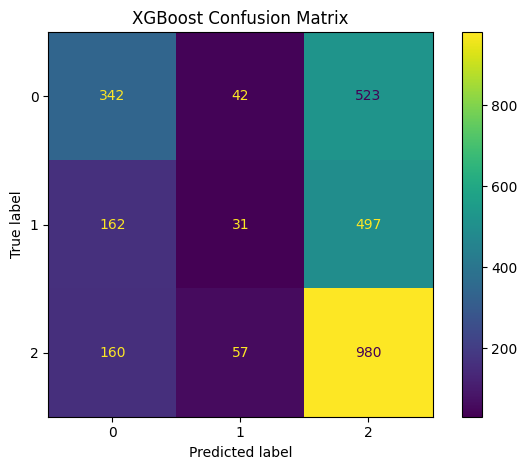

/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run xgb_baseline_shap at: http://100.116.34.36:8080/#/experiments/4/runs/4d6eb7d8b1c24c98be285d5cfe552fee
🧪 View experiment at: http://100.116.34.36:8080/#/experiments/4


In [37]:
# ------------------------------------------------------------
# 0. Kiểm tra và chuẩn hóa dữ liệu đầu vào
# ------------------------------------------------------------

# XGBoost hỗ trợ NaN nhưng không hỗ trợ +/- infinity
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_valid = X_valid.replace([np.inf, -np.inf], np.nan)
X_test  = X_test.replace([np.inf, -np.inf], np.nan)

# Đảm bảo thứ tự feature đồng nhất giữa các tập
X_valid = X_valid.reindex(columns=X_train.columns)
X_test = X_test.reindex(columns=X_train.columns)
features = list(X_train.columns)

# Đồng bộ tên feature cho phần SHAP
assert list(X_valid.columns) == features
assert list(X_test.columns) == features

# Kiểm tra nhãn
print("XGBoost version:", xgb.__version__)
print("SHAP version:", shap.__version__)
print("Số features:", len(features))
print("Các lớp train:", sorted(pd.Series(y_train).unique()))
print("Kích thước train/valid/test:",
      X_train.shape, X_valid.shape, X_test.shape)

# Lưu ý: xác minh mapping lớp 0/1/2 trước khi diễn giải
# tên lớp là khách thắng / hòa / đội nhà thắng.
if "y_result" in df.columns:
    print("\nMapping nhãn có trong dữ liệu:")
    display(
        df[["y_result_code", "y_result"]]
        .drop_duplicates()
        .sort_values("y_result_code")
    )

# ------------------------------------------------------------
# 5. Huấn luyện mô hình và ghi MLflow
# ------------------------------------------------------------

params = {
    "objective": "multi:softprob",
    "num_class": 3,
    "learning_rate": 0.05,
    "max_depth": 4,
    "n_estimators": 500,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "eval_metric": "mlogloss",
    "early_stopping_rounds": 30,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1
}

# Lưu hình vào thư mục để log thành artifact
os.makedirs("mlflow_artifacts", exist_ok=True)

with mlflow.start_run(run_name="xgb_baseline_shap") as run:
    run_id = run.info.run_id


    mlflow.log_params(params)
    mlflow.log_param("n_features", len(features))
    mlflow.log_param("n_train", len(X_train))
    mlflow.log_param("n_valid", len(X_valid))
    mlflow.log_param("n_test", len(X_test))

    model = xgb.XGBClassifier(**params)

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_valid, y_valid)],
        verbose=50
    )

    # Dự đoán trên test
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    loss = log_loss(
        y_test, y_prob, labels=model.classes_
    )

    print("\n===== KẾT QUẢ XGBOOST =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Macro F1 : {macro_f1:.4f}")
    print(f"Log Loss : {loss:.4f}")
    print("Best iteration:", getattr(model, "best_iteration", None))

    # Ghi metric vào MLflow
    mlflow.log_metrics({
        "accuracy": float(acc),
        "macro_f1": float(macro_f1),
        "log_loss": float(loss)
    })

    print("\n===== CLASSIFICATION REPORT =====")
    report = classification_report(
        y_test,
        y_pred,
        labels=model.classes_,
        zero_division=0
    )
    print(report)

    # Lưu báo cáo vào artifact
    report_path = "mlflow_artifacts/classification_report.txt"
    with open(report_path, "w", encoding="utf-8") as f:
        f.write(report)
    mlflow.log_artifact(report_path)

    # Confusion matrix
    cm = confusion_matrix(
        y_test, y_pred, labels=model.classes_
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )
    disp.plot()
    plt.title("XGBoost Confusion Matrix")
    plt.tight_layout()

    cm_path = "mlflow_artifacts/confusion_matrix.png"
    plt.savefig(cm_path, dpi=150, bbox_inches="tight")
    mlflow.log_artifact(cm_path)
    plt.show()
    plt.close()

    # Log model qua tiện ích hiện có của bạn

    X_train = X_train.apply(pd.to_numeric, errors="coerce").astype("float64")
    colab_utils.log_model(
        model,
        artifact_path="xgboost_model",
        input_example=X_train.head(3),
    )




SHAP output theo lớp: [(500, 148), (500, 148), (500, 148)]

SHAP Summary Plot - class 2


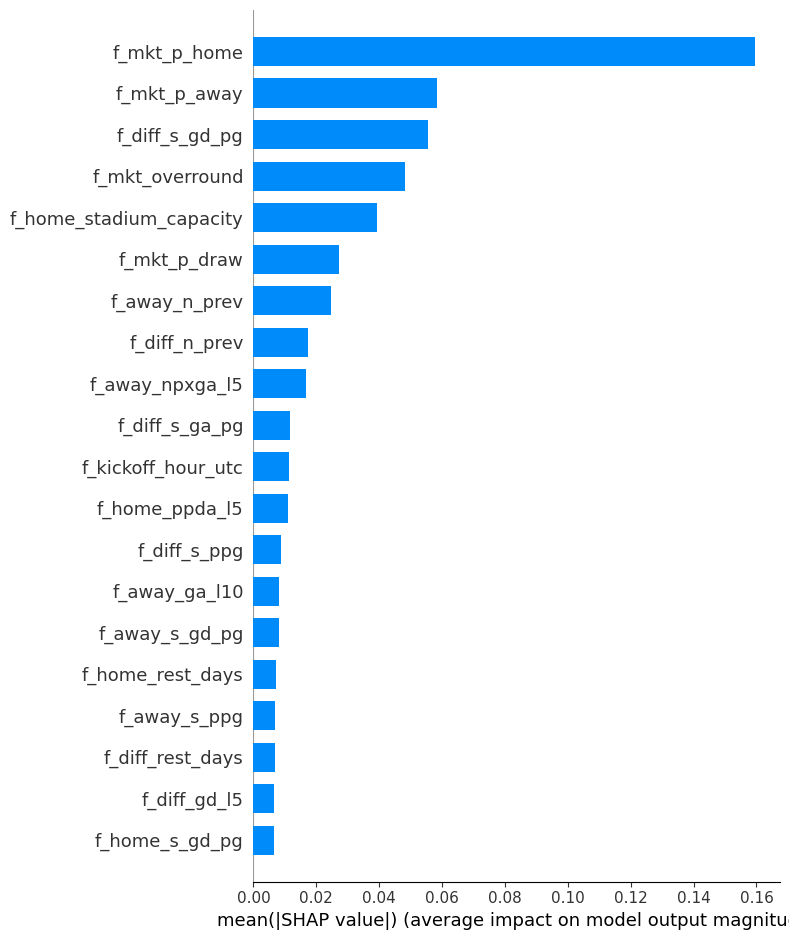

SHAP Beeswarm Plot - class 2


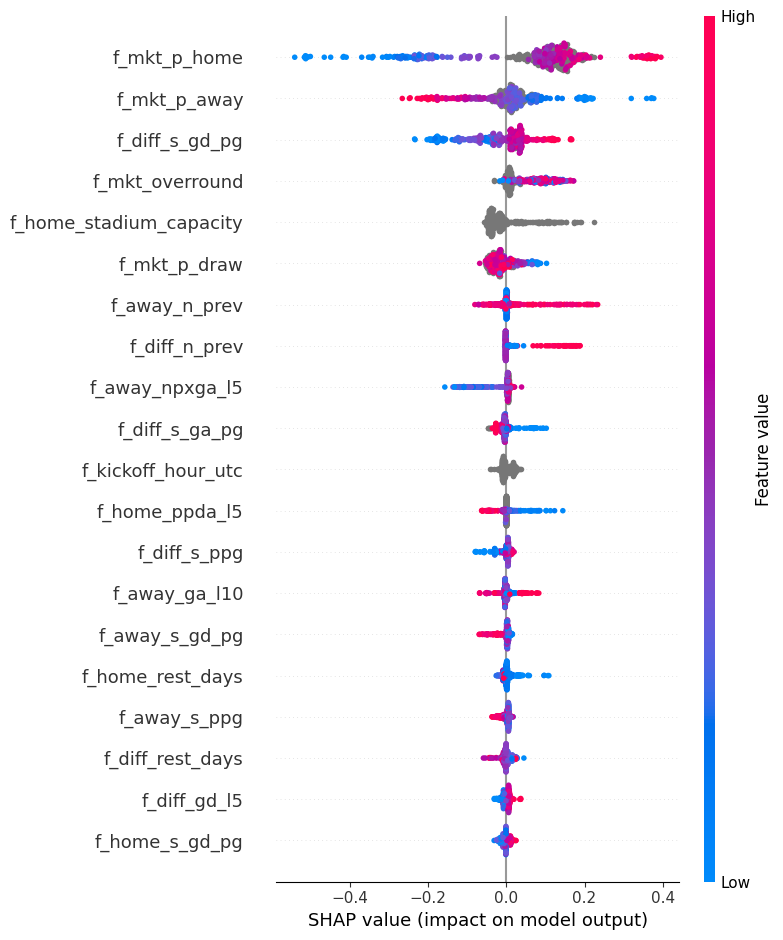

In [38]:
# --------------------------------------------------------
# 6. SHAP: giải thích mức độ ảnh hưởng của các feature
# --------------------------------------------------------

# Giới hạn số dòng để tránh tốn RAM/thời gian trên Colab
mlflow.start_run(run_id=run_id)

n_shap = min(500, len(X_test))
X_shap = X_test.iloc[:n_shap].copy()

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)

# Chuẩn hóa output giữa các phiên bản SHAP:
# - List: mỗi phần tử ứng với một lớp
# - Array: thường có shape (samples, features, classes)
if isinstance(shap_values, list):
    shap_by_class = shap_values
else:
    shap_values = np.asarray(shap_values)

    if shap_values.ndim == 3:
        # samples x features x classes
        shap_by_class = [
            shap_values[:, :, i]
            for i in range(shap_values.shape[2])
        ]
    elif shap_values.ndim == 2:
        # Trường hợp chỉ có một output
        shap_by_class = [shap_values]
    else:
        raise ValueError(
            f"SHAP output shape không hỗ trợ: {shap_values.shape}"
        )

print("\nSHAP output theo lớp:",
      [np.asarray(v).shape for v in shap_by_class])

# Chọn lớp 2 để phân tích.
# Chỉ gọi đây là "đội nhà thắng" sau khi xác minh mapping nhãn.
class_idx = 2

if class_idx >= len(shap_by_class):
    raise ValueError("Không tìm thấy SHAP values cho lớp đã chọn.")

sv_class = np.asarray(shap_by_class[class_idx])

# Summary plot dạng bar
print(f"\nSHAP Summary Plot - class {class_idx}")
plt.figure()
shap.summary_plot(
    sv_class,
    X_shap,
    plot_type="bar",
    show=False
)
plt.tight_layout()

summary_bar_path = "mlflow_artifacts/shap_summary_bar.png"
plt.savefig(summary_bar_path, dpi=150, bbox_inches="tight")
mlflow.log_artifact(summary_bar_path)
plt.show()
plt.close()

# Beeswarm: chiều và mức độ ảnh hưởng của feature
print(f"SHAP Beeswarm Plot - class {class_idx}")
plt.figure()
shap.summary_plot(
    sv_class,
    X_shap,
    show=False
)
plt.tight_layout()

beeswarm_path = "mlflow_artifacts/shap_beeswarm.png"
plt.savefig(beeswarm_path, dpi=150, bbox_inches="tight")
mlflow.log_artifact(beeswarm_path)
plt.show()
plt.close()




===== PHÂN TÍCH MỘT TRẬN =====
Trận đấu: Ipswich Town vs Blackburn
Nhãn thực tế: 2
Nhãn dự đoán: 2
Xác suất theo model.classes_:
{np.int64(0): np.float32(0.1407377), np.int64(1): np.float32(0.2152141), np.int64(2): np.float32(0.6440482)}


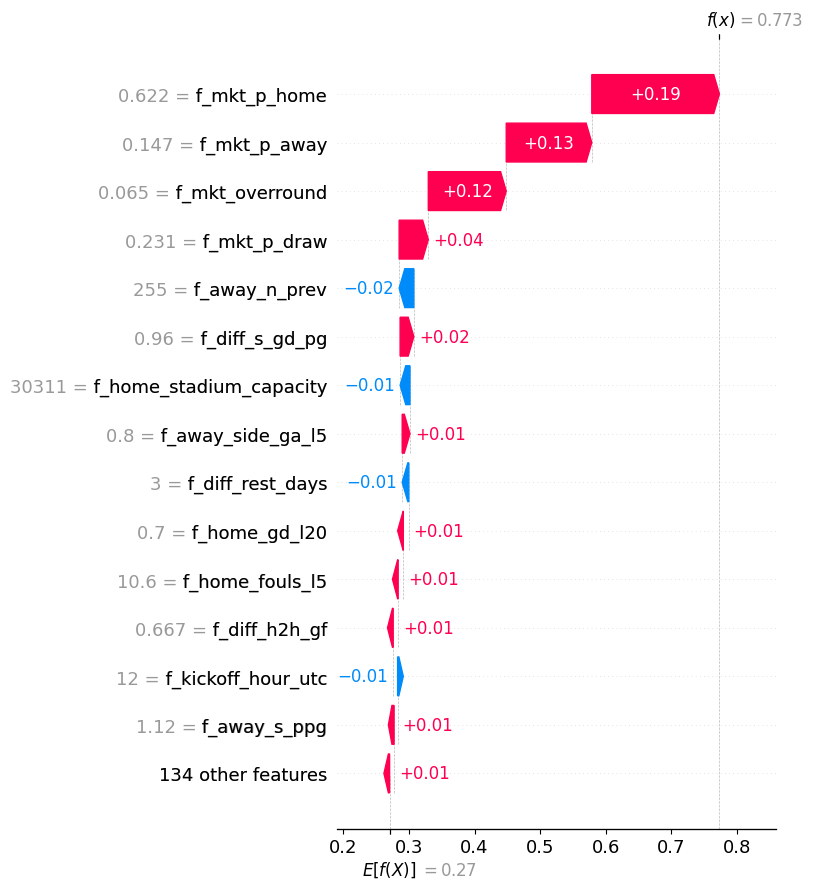


Đã log metric, báo cáo, biểu đồ và model vào MLflow.


In [40]:
# --------------------------------------------------------
# 7. Waterfall: giải thích một trận trong tập test
# --------------------------------------------------------
row_idx = 0

# X_shap lấy từ đầu X_test nên row_idx vẫn đồng bộ
# với test_df nếu test_df và X_test được tạo cùng thứ tự.
if row_idx >= len(X_shap) or row_idx >= len(test_df):
    raise IndexError("row_idx nằm ngoài phạm vi dữ liệu test.")

match_info = test_df.iloc[row_idx]

# Dùng tên cột thực tế trong dataset
home = match_info.get(
    "team_home", match_info.get("home_key", "Home")
)
away = match_info.get(
    "team_away", match_info.get("away_key", "Away")
)

actual = y_test.iloc[row_idx] if hasattr(y_test, "iloc") else y_test[row_idx]
predicted = y_pred[row_idx]
probabilities = y_prob[row_idx]

print("\n===== PHÂN TÍCH MỘT TRẬN =====")
print(f"Trận đấu: {home} vs {away}")
print(f"Nhãn thực tế: {actual}")
print(f"Nhãn dự đoán: {predicted}")
print("Xác suất theo model.classes_:")
print(dict(zip(model.classes_, probabilities)))

# Lấy SHAP value của đúng trận và đúng lớp
row_shap = sv_class[row_idx]

expected_values = np.asarray(explainer.expected_value)
if expected_values.ndim == 0:
    base_value = float(expected_values)
else:
    base_value = float(expected_values[class_idx])

explanation = shap.Explanation(
    values=row_shap,
    base_values=base_value,
    data=X_shap.iloc[row_idx].to_numpy(),
    feature_names=features
)

shap.plots.waterfall(explanation, max_display=15, show=False)
plt.tight_layout()

waterfall_path = "mlflow_artifacts/shap_waterfall.png"
plt.savefig(waterfall_path, dpi=150, bbox_inches="tight")
mlflow.log_artifact(waterfall_path)
plt.show()
plt.close()

print("\nĐã log metric, báo cáo, biểu đồ và model vào MLflow.")
